In [ ]:
# Repo bootstrap: notebooks use paths relative to the repo root and import from src/
import os, sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [1]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

import albumentations as A

import augly.image as imaugs
from augly.image import transforms as imaugs_t
from augly.image.composition import Compose, OneOf

import Augmentor

from tqdm import tqdm

In [3]:
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

NumPy: 2.4.2
OpenCV: 4.13.0


In [4]:
# Albumentations test
_ = A.HorizontalFlip(p=1)

In [5]:
# AugLy test
_ = imaugs_t.Rotate(degrees=10)

In [6]:
# Augmentor test
_ = Augmentor.Pipeline(".")

Initialised with 0 image(s) found.
Output directory set to ./output.

In [7]:
DATA_ROOT = Path("./data/TreeBoxes_v0.10")
IMAGES_DIR = DATA_ROOT/"images"
PATCH_DIR = Path("./patches_dataset/patches_v1_seed42")
NEG_PATCHES = PATCH_DIR/"negative"
POS_PATCHES = PATCH_DIR/"positive"
CSV_PATH = DATA_ROOT/"random.csv"

In [8]:
#img normale
image_files = list(IMAGES_DIR.glob("*.*"))
print(f"{len(image_files)} images trouvées")

img_path = image_files[4]
print("Image sélectionnée :", img_path.name)

img_bgr = cv2.imread(str(img_path))
assert img_bgr is not None, "Erreur lecture image"

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("Shape image originale :", img_rgb.shape)

11 images trouvées
Image sélectionnée : Carlos Vera Guevara RGB_5_3800_3800_7800_7800.png
Shape image originale : (4000, 4000, 3)


In [9]:
# list images : genralisation 
def list_images(folder: Path):
    exts = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp", ".webp"}
    files = sorted([f for f in folder.glob("*") if f.is_file() and f.suffix.lower() in exts])
    return files

def read_rgb(path: Path):
    bgr = cv2.imread(str(path))
    if bgr is None:
        return None
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# og
image_files = list_images(IMAGES_DIR)
print(f"{len(image_files)} images trouvées")
img_path = image_files[4]
img_rgb = read_rgb(img_path)
assert img_rgb is not None, f"Erreur lecture image: {img_path}"
print("Image sélectionnée :", img_path.name, "shape:", img_rgb.shape)

# pos
pos_files = list_images(POS_PATCHES)
print(f"{len(pos_files)} patches positifs trouvés")
pos_path = pos_files[4]
pos_rgb = read_rgb(pos_path)
assert pos_rgb is not None, f"Erreur lecture patch positif: {pos_path}"
print("Patch positif :", pos_path.name, "shape:", pos_rgb.shape)

# neg
neg_files = list_images(NEG_PATCHES)
print(f"{len(neg_files)} patches négatifs trouvés")
neg_path = neg_files[4]
neg_rgb = read_rgb(neg_path)
assert neg_rgb is not None, f"Erreur lecture patch négatif: {neg_path}"
print("Patch négatif :", neg_path.name, "shape:", neg_rgb.shape)


11 images trouvées
Image sélectionnée : B09_0098.JPG shape: (1500, 1500, 3)
5294 patches positifs trouvés
Patch positif : 1000.png shape: (224, 224, 3)
3526 patches négatifs trouvés
Patch négatif : 1000.png shape: (224, 224, 3)


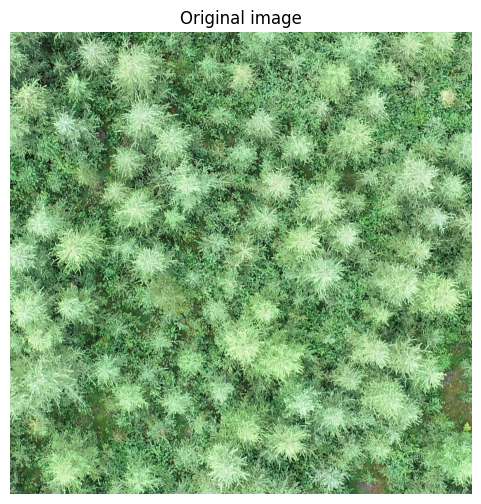

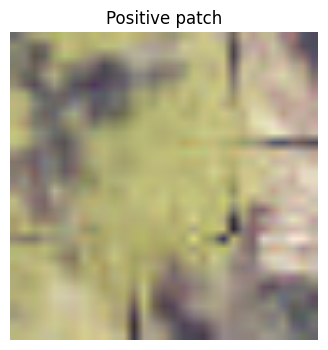

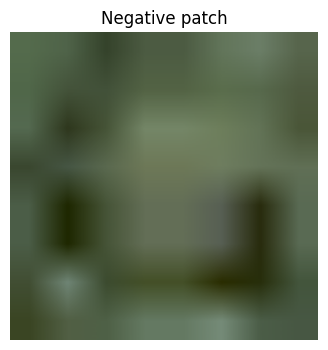

In [10]:
plt.figure(figsize=(6,6))
plt.imshow(img_rgb)
plt.title("Original image")
plt.axis("off")
plt.show()

plt.figure(figsize=(4,4))
plt.imshow(pos_rgb)
plt.title("Positive patch")
plt.axis("off")
plt.show()

plt.figure(figsize=(4,4))
plt.imshow(neg_rgb)
plt.title("Negative patch")
plt.axis("off")
plt.show()

In [11]:
# augly 

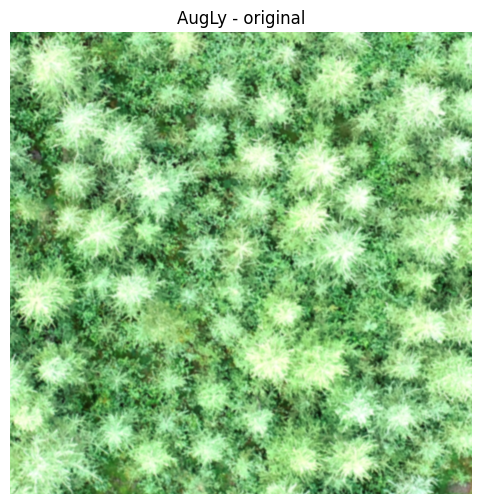

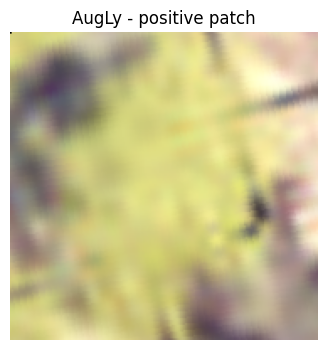

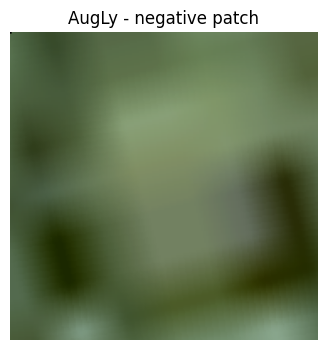

In [12]:
augly_pipe = Compose([
    imaugs_t.Brightness(factor=1.15),
    imaugs_t.Contrast(factor=1.15),
    imaugs_t.Blur(radius=2),
    imaugs_t.Rotate(degrees=15),
])

def augly_apply(rgb_np):
    pil = Image.fromarray(rgb_np)
    out = augly_pipe(pil)
    return np.array(out)

augly_img = augly_apply(img_rgb)
augly_pos = augly_apply(pos_rgb)
augly_neg = augly_apply(neg_rgb)

for title, im in [("AugLy - original", augly_img),
                  ("AugLy - positive patch", augly_pos),
                  ("AugLy - negative patch", augly_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im)
    plt.title(title)
    plt.axis("off")
    plt.show()

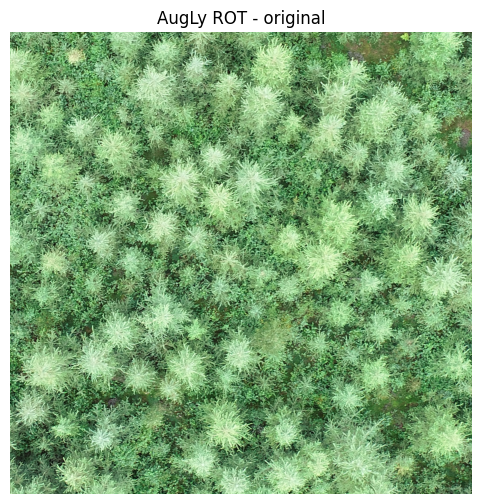

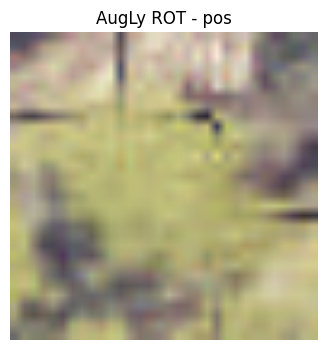

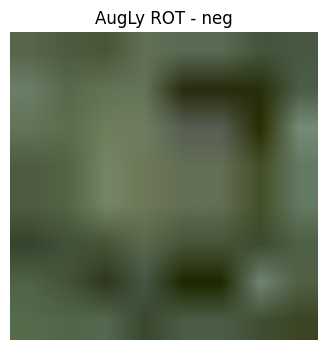

In [13]:
rot_augly = Compose([
    imaugs_t.Rotate(degrees=90),
])

def augly_apply(pipe, rgb_np):
    out = pipe(Image.fromarray(rgb_np))
    return np.array(out)

augly_img = augly_apply(rot_augly, img_rgb)
augly_pos = augly_apply(rot_augly, pos_rgb)
augly_neg = augly_apply(rot_augly, neg_rgb)

for title, im in [("AugLy ROT - original", augly_img),
                  ("AugLy ROT - pos", augly_pos),
                  ("AugLy ROT - neg", augly_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im); plt.title(title); plt.axis("off"); plt.show()

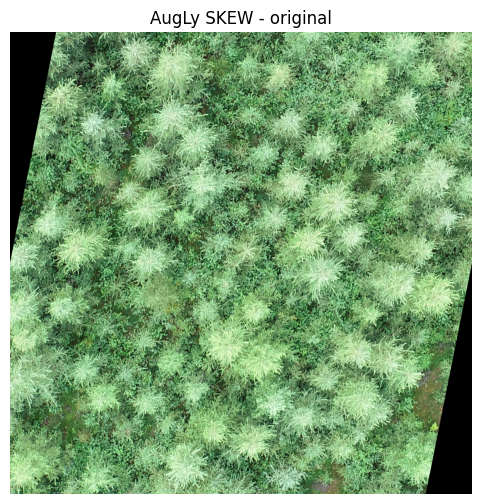

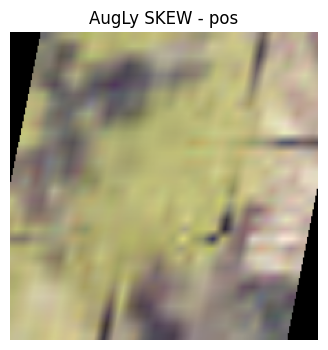

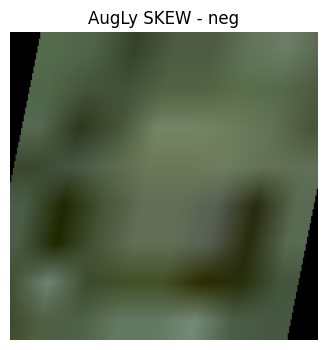

In [17]:
persp_augly = Compose([
    imaugs_t.Skew(skew_factor=0.2)  
])

def augly_apply(pipe, rgb_np):
    return np.array(pipe(Image.fromarray(rgb_np)))

augly_img = augly_apply(persp_augly, img_rgb)
augly_pos = augly_apply(persp_augly, pos_rgb)
augly_neg = augly_apply(persp_augly, neg_rgb)

for title, im in [("AugLy SKEW - original", augly_img),
                  ("AugLy SKEW - pos", augly_pos),
                  ("AugLy SKEW - neg", augly_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im); plt.title(title); plt.axis("off"); plt.show()

In [19]:
# augmentor

In [ ]:
tmp_root = Path("_tmp_augm_rot")
if tmp_root.exists(): shutil.rmtree(tmp_root)
tmp_root.mkdir(parents=True, exist_ok=True)

def augmentor_apply_rotate(rgb_np, name):
    in_dir = tmp_root / f"in_{name}"
    out_dir = tmp_root / f"out_{name}"
    in_dir.mkdir(parents=True, exist_ok=True)
    out_dir.mkdir(parents=True, exist_ok=True)

    cv2.imwrite(str(in_dir / "img.png"), cv2.cvtColor(rgb_np, cv2.COLOR_RGB2BGR))

    p = Augmentor.Pipeline(str(in_dir), output_directory=str(out_dir))
    p.rotate(probability=1, max_left_rotation=15, max_right_rotation=15)
    p.sample(1)

    outs = sorted(out_dir.glob("*.png"))
    bgr = cv2.imread(str(outs[-1]))
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

augm_img = augmentor_apply_rotate(img_rgb, "orig")
augm_pos = augmentor_apply_rotate(pos_rgb, "pos")
augm_neg = augmentor_apply_rotate(neg_rgb, "neg")

for title, im in [("Augmentor ROT - original", augm_img),
                  ("Augmentor ROT - pos", augm_pos),
                  ("Augmentor ROT - neg", augm_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im); plt.title(title); plt.axis("off"); plt.show()

Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_shear/out_orig.

Processing <PIL.Image.Image image mode=RGB size=1500x1500 at 0x15702AF10>: 100%|


Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_shear/out_pos.

Processing <PIL.Image.Image image mode=RGB size=224x224 at 0x1564D95D0>: 100%|█|


Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_shear/out_neg.

Processing <PIL.Image.Image image mode=RGB size=224x224 at 0x1507DC1D0>: 100%|█|


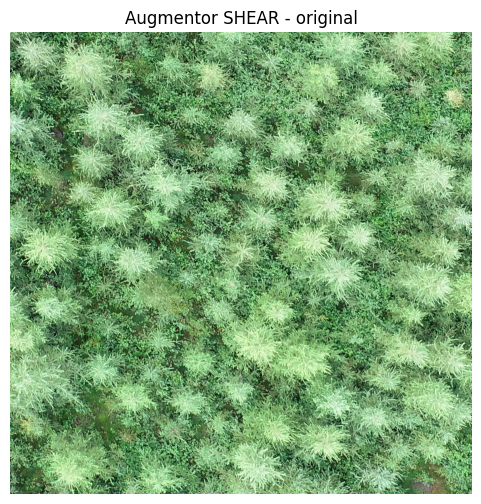

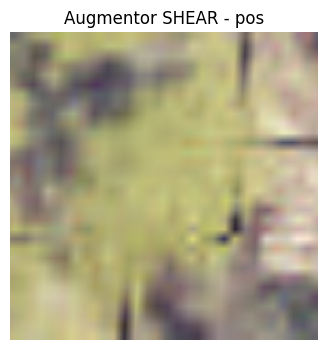

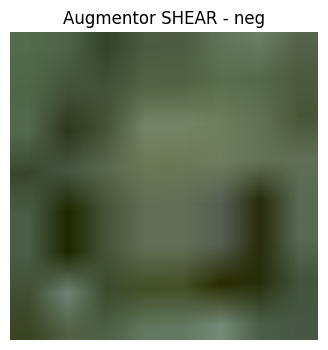

In [38]:
import shutil
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import Augmentor

tmp_root = Path("_tmp_augm_shear")
if tmp_root.exists():
    shutil.rmtree(tmp_root)
tmp_root.mkdir(parents=True, exist_ok=True)

def find_first_image(folder: Path):
    exts = {".png", ".jpg", ".jpeg"}
    files = sorted([p for p in folder.rglob("*") if p.suffix.lower() in exts])
    return files[-1] if files else None

def augmentor_apply_shear(rgb_np, name):
    in_dir = (tmp_root / f"in_{name}").resolve()
    out_dir = (tmp_root / f"out_{name}").resolve()
    in_dir.mkdir(parents=True, exist_ok=True)
    out_dir.mkdir(parents=True, exist_ok=True)

    cv2.imwrite(str(in_dir / "img.png"), cv2.cvtColor(rgb_np, cv2.COLOR_RGB2BGR))

    p = Augmentor.Pipeline(source_directory=str(in_dir), output_directory=str(out_dir))
    p.shear(probability=1, max_shear_left=10, max_shear_right=10)
    p.sample(1)

    out_path = find_first_image(out_dir)
    assert out_path is not None, f"Aucune sortie trouvée dans {out_dir}"
    bgr = cv2.imread(str(out_path))
    assert bgr is not None, f"imread failed: {out_path}"
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

augm_img = augmentor_apply_shear(img_rgb, "orig")
augm_pos = augmentor_apply_shear(pos_rgb, "pos")
augm_neg = augmentor_apply_shear(neg_rgb, "neg")

for title, im in [("Augmentor SHEAR - original", augm_img),
                  ("Augmentor SHEAR - pos", augm_pos),
                  ("Augmentor SHEAR - neg", augm_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im)
    plt.title(title)
    plt.axis("off")
    plt.show()

Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_rot/out_orig.

Processing <PIL.Image.Image image mode=RGB size=1500x1500 at 0x1570DF090>: 100%|


Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_rot/out_pos.

Processing <PIL.Image.Image image mode=RGB size=224x224 at 0x15084AC10>: 100%|█|


Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_rot/out_neg.

Processing <PIL.Image.Image image mode=RGB size=224x224 at 0x1583561D0>: 100%|█|


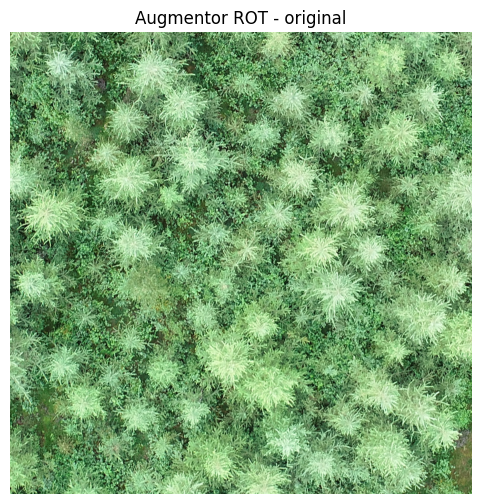

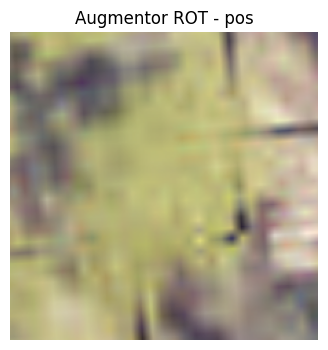

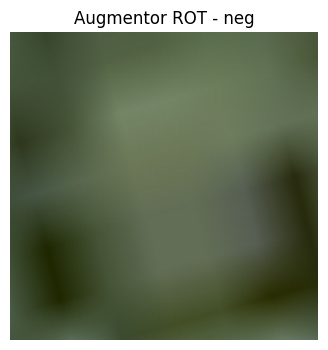

In [32]:
tmp_root = Path("_tmp_augm_rot")
if tmp_root.exists():
    shutil.rmtree(tmp_root)
tmp_root.mkdir(parents=True, exist_ok=True)

def find_first_image(folder: Path):
    exts = {".png", ".jpg", ".jpeg"}
    files = sorted([p for p in folder.rglob("*") if p.suffix.lower() in exts])
    return files[-1] if files else None

def augmentor_apply_rotate(rgb_np, name):
    in_dir = (tmp_root / f"in_{name}").resolve()
    out_dir = (tmp_root / f"out_{name}").resolve()

    in_dir.mkdir(parents=True, exist_ok=True)
    out_dir.mkdir(parents=True, exist_ok=True)

    # write input
    cv2.imwrite(str(in_dir / "img.png"), cv2.cvtColor(rgb_np, cv2.COLOR_RGB2BGR))

    p = Augmentor.Pipeline(source_directory=str(in_dir), output_directory=str(out_dir))
    p.rotate(probability=1, max_left_rotation=15, max_right_rotation=15)
    p.sample(1)

    out_path = find_first_image(out_dir)
    assert out_path is not None, f"Aucune sortie trouvée dans {out_dir}"

    bgr = cv2.imread(str(out_path))
    assert bgr is not None, f"imread failed: {out_path}"
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

augm_img = augmentor_apply_rotate(img_rgb, "orig")
augm_pos = augmentor_apply_rotate(pos_rgb, "pos")
augm_neg = augmentor_apply_rotate(neg_rgb, "neg")

for title, im in [("Augmentor ROT - original", augm_img),
                  ("Augmentor ROT - pos", augm_pos),
                  ("Augmentor ROT - neg", augm_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im); plt.title(title); plt.axis("off"); plt.show()

Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_dist/out_orig.

Processing <PIL.Image.Image image mode=RGB size=1500x1500 at 0x1570F3650>: 100%|


Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_dist/out_pos.

Processing <PIL.Image.Image image mode=RGB size=224x224 at 0x1570F3D10>: 100%|█|


Initialised with 1 image(s) found.
Output directory set to /Users/zahra/Files/M1-MIND/trees_project_2026/_tmp_augm_dist/out_neg.

Processing <PIL.Image.Image image mode=RGB size=224x224 at 0x1571213D0>: 100%|█|


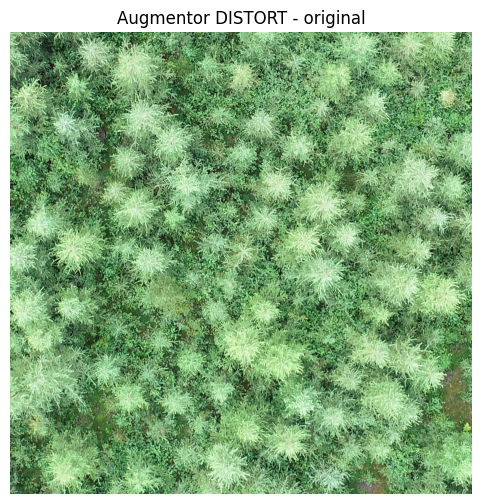

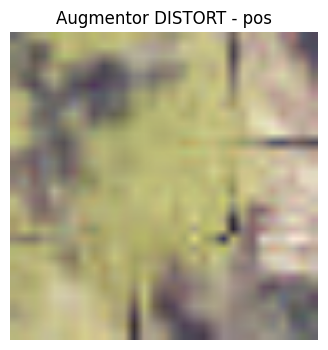

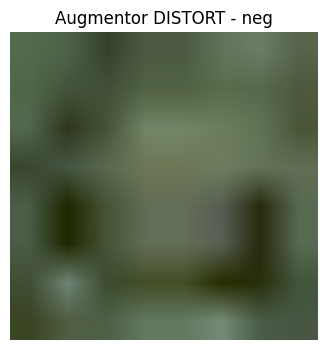

In [36]:
tmp_root = Path("_tmp_augm_dist")
if tmp_root.exists():
    shutil.rmtree(tmp_root)
tmp_root.mkdir(parents=True, exist_ok=True)

def find_first_image(folder: Path):
    exts = {".png", ".jpg", ".jpeg"}
    files = sorted([p for p in folder.rglob("*") if p.suffix.lower() in exts])
    return files[-1] if files else None

def augmentor_apply_distortion(rgb_np, name):
    in_dir = (tmp_root / f"in_{name}").resolve()
    out_dir = (tmp_root / f"out_{name}").resolve()

    in_dir.mkdir(parents=True, exist_ok=True)
    out_dir.mkdir(parents=True, exist_ok=True)

    # write input
    cv2.imwrite(str(in_dir / "img.png"), cv2.cvtColor(rgb_np, cv2.COLOR_RGB2BGR))

    p = Augmentor.Pipeline(source_directory=str(in_dir),
                           output_directory=str(out_dir))

    p.gaussian_distortion(
        probability=1,
        grid_width=4,
        grid_height=4,
        magnitude=2,
        corner="bell",    
        method="in"       
        
    )

    p.sample(1)

    out_path = find_first_image(out_dir)
    assert out_path is not None, f"Aucune sortie trouvée dans {out_dir}"

    bgr = cv2.imread(str(out_path))
    assert bgr is not None, f"imread failed: {out_path}"

    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

augm_img = augmentor_apply_distortion(img_rgb, "orig")
augm_pos = augmentor_apply_distortion(pos_rgb, "pos")
augm_neg = augmentor_apply_distortion(neg_rgb, "neg")

for title, im in [("Augmentor DISTORT - original", augm_img),
                  ("Augmentor DISTORT - pos", augm_pos),
                  ("Augmentor DISTORT - neg", augm_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im)
    plt.title(title)
    plt.axis("off")
    plt.show()

In [23]:
# albumentations

/Users/zahra/Files/M1-MIND/mt311/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


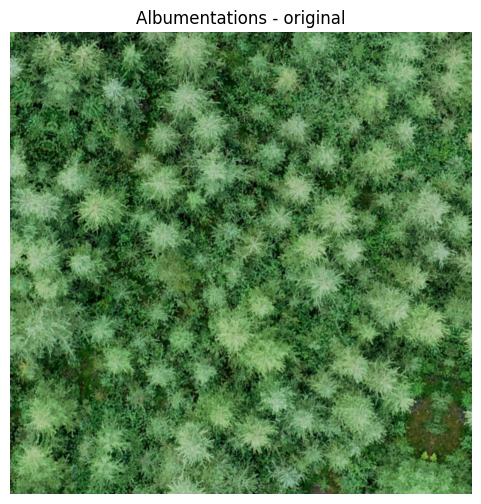

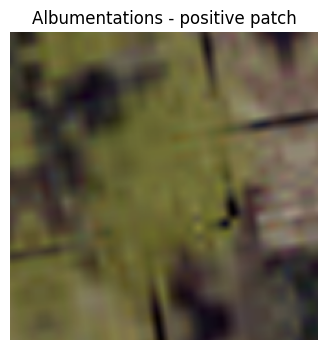

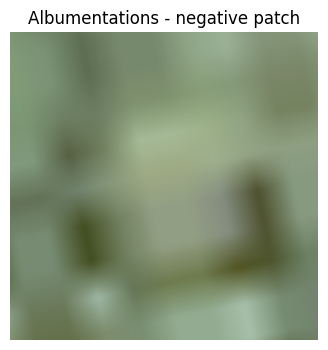

In [24]:
alb = A.Compose([
    A.RandomBrightnessContrast(p=1.0),
    A.GaussianBlur(blur_limit=(3, 7), p=1.0),
    A.ShiftScaleRotate(
        shift_limit=0.02, scale_limit=0.10, rotate_limit=15,
        border_mode=cv2.BORDER_REFLECT_101, p=1.0
    ),
])

alb_img = alb(image=img_rgb)["image"]
alb_pos = alb(image=pos_rgb)["image"]
alb_neg = alb(image=neg_rgb)["image"]

for title, im in [("Albumentations - original", alb_img),
                  ("Albumentations - positive patch", alb_pos),
                  ("Albumentations - negative patch", alb_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im)
    plt.title(title)
    plt.axis("off")
    plt.show()

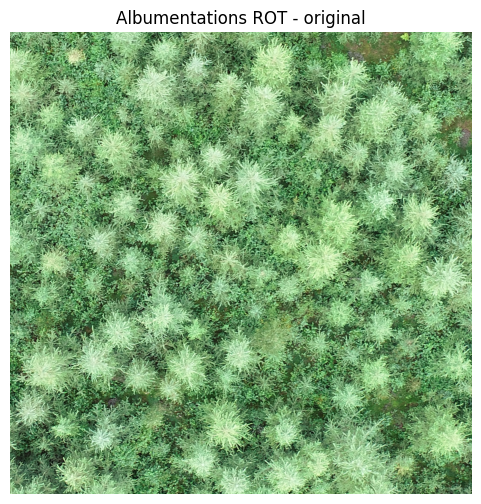

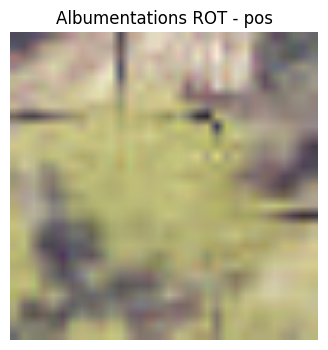

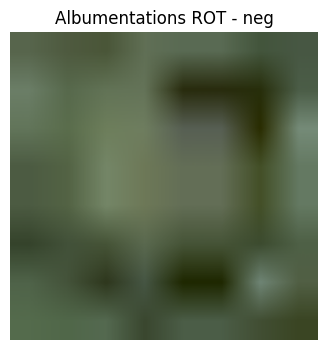

In [25]:
rot_alb = A.Compose([
    A.Rotate(limit=(90, 90), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
])

alb_img = rot_alb(image=img_rgb)["image"]
alb_pos = rot_alb(image=pos_rgb)["image"]
alb_neg = rot_alb(image=neg_rgb)["image"]

for title, im in [("Albumentations ROT - original", alb_img),
                  ("Albumentations ROT - pos", alb_pos),
                  ("Albumentations ROT - neg", alb_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im); plt.title(title); plt.axis("off"); plt.show()

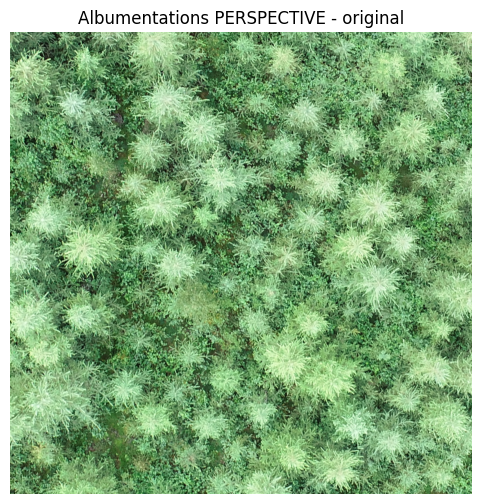

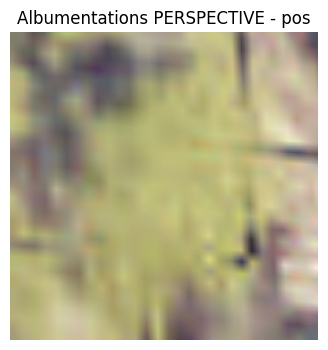

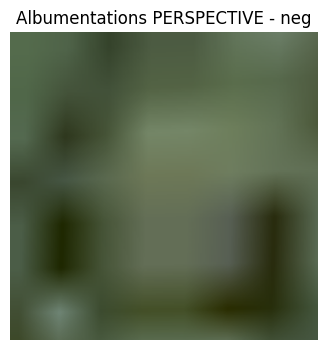

In [26]:
persp_alb = A.Compose([
    A.Perspective(scale=(0.001, 0.05), keep_size=True, p=1.0),
])

alb_img = persp_alb(image=img_rgb)["image"]
alb_pos = persp_alb(image=pos_rgb)["image"]
alb_neg = persp_alb(image=neg_rgb)["image"]

for title, im in [("Albumentations PERSPECTIVE - original", alb_img),
                  ("Albumentations PERSPECTIVE - pos", alb_pos),
                  ("Albumentations PERSPECTIVE - neg", alb_neg)]:
    plt.figure(figsize=(6,6) if "original" in title else (4,4))
    plt.imshow(im); plt.title(title); plt.axis("off"); plt.show()